[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/05-deep-learning/notebooks/01-tensors-and-autograd.ipynb)

# 05-01 · Tensors and autograd: PyTorch from zero

**Goal:** learn the two building blocks of PyTorch.
1. **Tensors** — PyTorch's arrays of numbers.
2. **Autograd** — PyTorch's automatic gradient calculator, the engine behind all neural-network training.

We finish by training a one-neuron "network" with gradient descent, first by hand and then the PyTorch way. Runs in seconds on CPU.

## Setup: device and reproducibility

- `device` is `"cuda"` if a GPU is available (e.g. Colab with a T4 GPU), otherwise `"cpu"`. All later code uses this variable, so the same notebook runs anywhere.
- `torch.manual_seed(0)` fixes the random starting weights so you get the same results each run.
- On CPU we use one thread: these models are tiny, and many threads fighting over tiny jobs is slower (especially on shared or busy machines).

In [1]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(1)
torch.manual_seed(0)
print("PyTorch", torch.__version__, "| running on:", device)

PyTorch 2.15.0+cpu | running on: cpu


## Part 1 · Tensors

A **tensor** is a grid of numbers with a **shape** (its size in each direction) and a **dtype** (the number type). It is like a NumPy array, but it can live on a GPU and can track gradients.

In [2]:
scalar = torch.tensor(3.5)                       # 0-D: a single number
vector = torch.tensor([1.0, 2.0, 3.0])           # 1-D: a list
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])  # 2-D: a table
for name, t in [("scalar", scalar), ("vector", vector), ("matrix", matrix)]:
    print(f"{name:6s} shape={tuple(t.shape)}  dims={t.ndim}  dtype={t.dtype}")

scalar shape=()  dims=0  dtype=torch.float32
vector shape=(3,)  dims=1  dtype=torch.float32
matrix shape=(2, 2)  dims=2  dtype=torch.float32


Ways to create tensors you will see constantly. `torch.rand` gives random numbers between 0 and 1; `torch.randn` gives random numbers from a bell curve centred on 0.

In [3]:
print(torch.zeros(2, 3))
print(torch.ones(2, 3))
print(torch.arange(6))           # 0,1,2,3,4,5
print(torch.rand(2, 2))
print(torch.randn(2, 2))

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([0, 1, 2, 3, 4, 5])
tensor([[0.4963, 0.7682],
        [0.0885, 0.1320]])
tensor([[-2.1788,  0.5684],
        [-1.0845, -1.3986]])


### Maths on tensors

Operations work **element by element** (each position separately), just like NumPy. `@` is **matrix multiplication** — the core operation inside every neural-network layer.

In [4]:
a = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
b = torch.tensor([[10.0, 20.0], [30.0, 40.0]])
print("a + b =\n", a + b)
print("a * b (element-wise) =\n", a * b)
print("a @ b (matrix multiply) =\n", a @ b)
print("sum:", a.sum().item(), " mean:", a.mean().item(), " max:", a.max().item())

a + b =
 tensor([[11., 22.],
        [33., 44.]])
a * b (element-wise) =
 tensor([[ 10.,  40.],
        [ 90., 160.]])
a @ b (matrix multiply) =
 tensor([[ 70., 100.],
        [150., 220.]])
sum: 10.0  mean: 2.5  max: 4.0


`.item()` turns a one-number tensor into a normal Python number.

### Reshaping

`reshape` (or `view`) changes the shape without changing the numbers. We will do this to turn a flat list of 64 pixels into an 8×8 image for the CNN. `-1` means "work this size out for me".

In [5]:
t = torch.arange(12)
print(t.reshape(3, 4))
print(t.reshape(2, -1).shape)        # -1 -> PyTorch works out 6
img_batch = torch.rand(5, 64).reshape(-1, 1, 8, 8)
print("batch of images:", tuple(img_batch.shape), "-> (batch, channels, height, width)")

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
torch.Size([2, 6])
batch of images: (5, 1, 8, 8) -> (batch, channels, height, width)


### dtype and the NumPy bridge

Neural-network inputs are usually `float32`. Class labels must be `long` (64-bit whole numbers). `torch.from_numpy` and `.numpy()` convert between PyTorch and NumPy.

In [6]:
import numpy as np
arr = np.array([1, 2, 3])
t = torch.from_numpy(arr)
print(t, t.dtype)
print(t.float(), t.float().dtype)
print(t.long().dtype)
print("back to numpy:", t.float().numpy())

tensor([1, 2, 3]) torch.int64
tensor([1., 2., 3.]) torch.float32
torch.int64
back to numpy: [1. 2. 3.]


### Devices

Every tensor lives on a **device**. `.to(device)` moves it. Tensors that are combined must be on the same device; mixing CPU and GPU tensors raises an error. On Colab with a GPU this prints `cuda:0`.

In [7]:
x = torch.rand(3).to(device)
print("x lives on:", x.device)
print("back on cpu for numpy:", x.cpu().numpy())

x lives on: cpu
back on cpu for numpy: [0.99880487 0.8173947  0.15438312]


## Part 2 · Autograd: automatic gradients

A **gradient** tells us how much a result changes when we nudge an input. If we create a tensor with `requires_grad=True`, PyTorch records every operation on it. Calling `.backward()` on the final result computes the gradient and stores it in `.grad`.

Example: `loss = (w − 5)²`. By hand, the slope is `2 × (w − 5)`. At `w = 3` that is `−4`.

In [8]:
w = torch.tensor(3.0, requires_grad=True)
loss = (w - 5) ** 2
loss.backward()
print("loss:", loss.item())
print("gradient d(loss)/dw:", w.grad.item(), " (by hand: 2*(3-5) = -4)")

loss: 4.0
gradient d(loss)/dw: -4.0  (by hand: 2*(3-5) = -4)


The gradient is negative, which means "increase `w` to make the loss smaller". That is exactly the information gradient descent needs.

Autograd works through any chain of operations, however long. Here `y` depends on `a` and `b` through several steps:

In [9]:
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(4.0, requires_grad=True)
y = a * b + a ** 3       # dy/da = b + 3a^2 = 4 + 12 = 16 ; dy/db = a = 2
y.backward()
print("dy/da =", a.grad.item(), "  dy/db =", b.grad.item())

dy/da = 16.0   dy/db = 2.0


### Gradients add up — the reason for `zero_grad()`

If you call `.backward()` twice without resetting, PyTorch **adds** the new gradient to the old one. In a training loop this would be a bug, which is why every loop calls `optimizer.zero_grad()`.

In [10]:
w = torch.tensor(3.0, requires_grad=True)
for i in range(3):
    loss = (w - 5) ** 2
    loss.backward()
    print(f"after backward #{i+1}: w.grad = {w.grad.item()}")
w.grad.zero_()
print("after zero_():", w.grad.item())

after backward #1: w.grad = -4.0
after backward #2: w.grad = -8.0
after backward #3: w.grad = -12.0
after zero_(): 0.0


## Part 3 · Gradient descent by hand

Let us fit a straight line `y = w·x + b` to noisy data whose true rule is `y = 2x + 1`. We start with random `w` and `b`, and repeat:

1. **forward:** predict and compute the MSE loss,
2. **backward:** get gradients,
3. **update:** `w = w − lr × w.grad` (inside `torch.no_grad()` so the update itself is not recorded),
4. reset the gradients.

In [11]:
torch.manual_seed(0)
x = torch.linspace(-1, 1, 50)
y_true = 2 * x + 1 + 0.2 * torch.randn(50)

w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
lr = 0.1
history = []
for step in range(100):
    pred = w * x + b                          # forward
    loss = ((pred - y_true) ** 2).mean()      # MSE loss
    loss.backward()                           # gradients for w and b
    with torch.no_grad():                     # update without recording
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_(); b.grad.zero_()            # reset for next step
    history.append(loss.item())
    if step % 20 == 0:
        print(f"step {step:3d}  loss={loss.item():.4f}  w={w.item():.3f}  b={b.item():.3f}")
print(f"final: w={w.item():.3f} (true 2), b={b.item():.3f} (true 1)")

step   0  loss=0.7299  w=0.755  b=0.953
step  20  loss=0.0835  w=1.748  b=1.009
step  40  loss=0.0474  w=1.984  b=1.010
step  60  loss=0.0453  w=2.040  b=1.010
step  80  loss=0.0452  w=2.053  b=1.010
final: w=2.056 (true 2), b=1.010 (true 1)


The loss falls quickly and `w`, `b` approach the true values 2 and 1. Here is the loss curve:

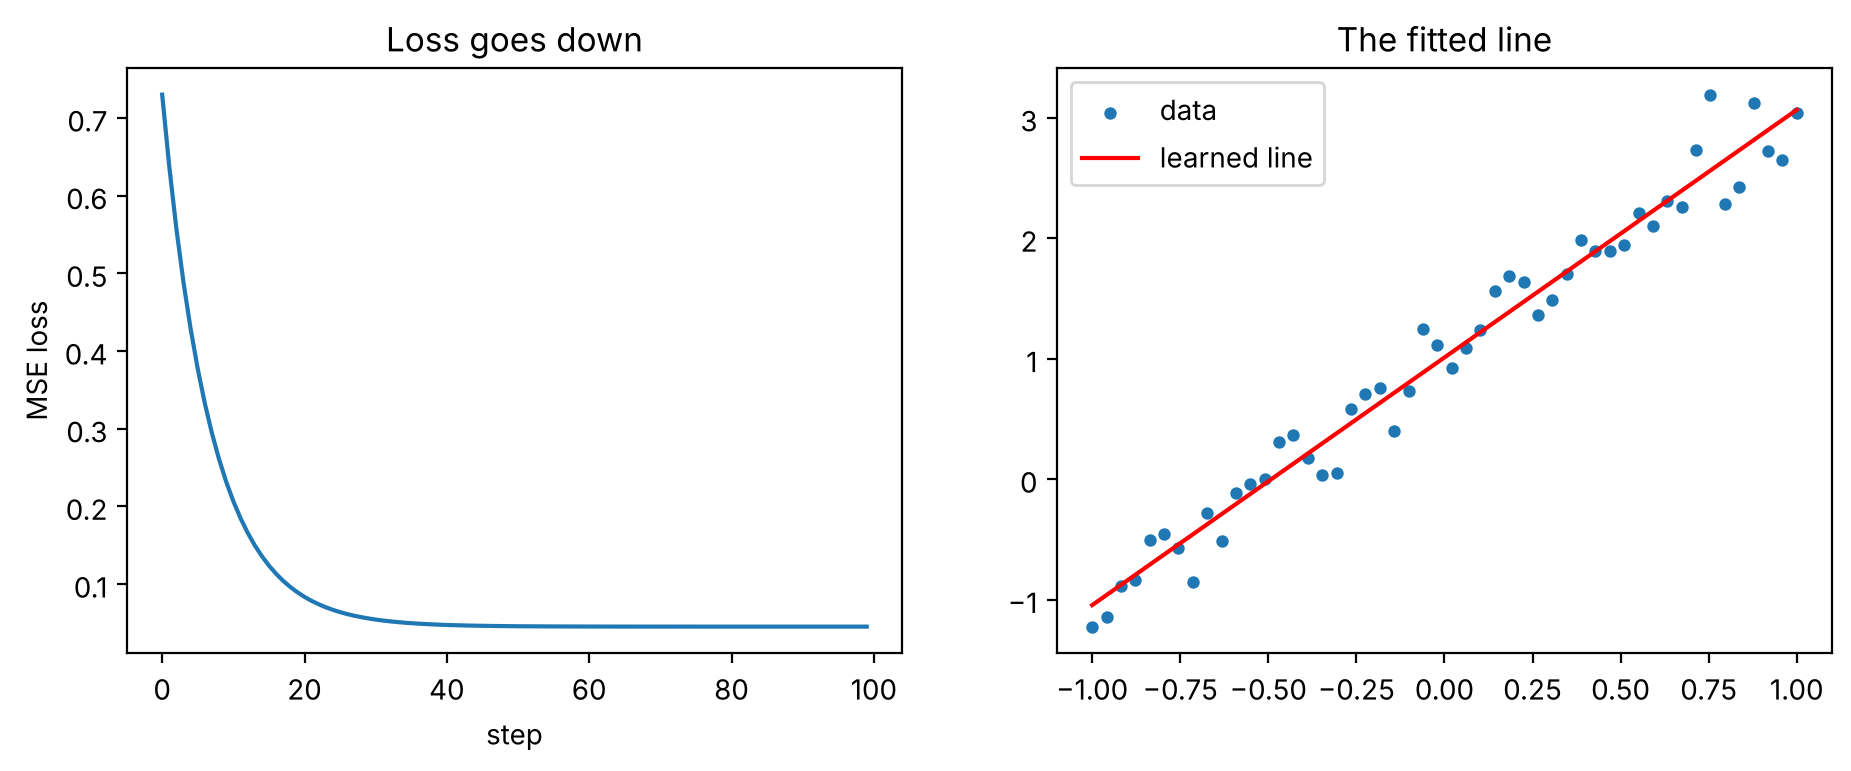

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(history); axes[0].set_xlabel("step"); axes[0].set_ylabel("MSE loss"); axes[0].set_title("Loss goes down")
axes[1].scatter(x, y_true, s=12, label="data")
axes[1].plot(x, (w * x + b).detach(), color="red", label="learned line")
axes[1].legend(); axes[1].set_title("The fitted line")
plt.show()

`.detach()` gives a copy of a tensor that is no longer tracked by autograd — needed before plotting or converting to NumPy.

## Part 4 · The same thing, the PyTorch way

In real code we do not write the update by hand. We use:
- `nn.Linear(1, 1)` — a layer holding `w` and `b` for us,
- `nn.MSELoss()` — the loss,
- `torch.optim.SGD` — an **optimizer** that performs `w = w − lr × grad` for every weight.

The loop now has the exact shape of every training loop you will ever write: forward → loss → zero_grad → backward → step.

In [13]:
import torch.nn as nn
torch.manual_seed(0)
model = nn.Linear(1, 1).to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
X_col = x.reshape(-1, 1).to(device)          # nn.Linear expects (rows, features)
Y_col = y_true.reshape(-1, 1).to(device)

for step in range(100):
    pred = model(X_col)                       # forward
    loss = loss_fn(pred, Y_col)               # how wrong?
    optimizer.zero_grad()                     # clear old gradients
    loss.backward()                           # compute new gradients
    optimizer.step()                          # update weights
print("learned weight:", model.weight.item(), " bias:", model.bias.item())

learned weight: 2.0558013916015625  bias: 1.0097637176513672


## Recap

- Tensors: shape, dtype, device; `@` for matrix multiply; `reshape`; `.item()`, `.numpy()`, `.detach()`, `.cpu()`.
- Autograd: `requires_grad=True` → `.backward()` → `.grad`.
- Gradients accumulate → always zero them.
- Training = forward → loss → zero_grad → backward → step, repeated.

**Try it:** set `lr = 1.5` in Part 3. What happens to the loss? (Too big a step overshoots the valley.)